# Métricas de flujo del fulfilment (P1, P2, M2)
Responsable: Persona 3 · Entrega 1 · Requiere `uv run novaretail all` antes de ejecutar.

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd() / "src", Path.cwd().parent / "src"]:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import pandas as pd
import matplotlib.pyplot as plt
from novaretail import flow
from novaretail.config import CLEAN, DATA_END, FIGURES

FIGURES.mkdir(parents=True, exist_ok=True)
events = pd.read_parquet(CLEAN / "fulfilment_events.parquet")
orders = pd.read_parquet(CLEAN / "orders.parquet")

## 1. Tiempos por etapa, P50 y P90 por almacén y transportista

,warehouse,n_orders,created_to_picked_p50,created_to_picked_p90,picked_to_packed_p50,picked_to_packed_p90,packed_to_shipped_p50,packed_to_shipped_p90,shipped_to_delivered_p50,shipped_to_delivered_p90,total_hours_p50,total_hours_p90
0,WH-BCN,12403,7.16,12.99,8.27,19.84,4.98,27.38,24.09,55.56,59.63,93.13
1,WH-BIO,8033,5.01,11.78,1.11,2.94,4.45,28.87,39.37,70.92,58.27,92.76
2,WH-MAD,13947,4.84,11.68,1.10,2.85,4.44,28.95,23.88,49.31,46.55,74.34
3,WH-SVQ,10667,4.98,11.69,1.11,2.98,4.38,28.71,24.97,52.46,47.42,79.00


,carrier,n_orders,created_to_picked_p50,created_to_picked_p90,picked_to_packed_p50,picked_to_packed_p90,packed_to_shipped_p50,packed_to_shipped_p90,shipped_to_delivered_p50,shipped_to_delivered_p90,total_hours_p50,total_hours_p90
0,EnviaYa,13061,5.46,12.05,1.37,10.18,4.57,28.44,26.46,48.33,49.41,76.60
1,PaqPlus,8259,5.31,11.99,1.37,10.03,4.62,28.63,32.42,69.35,59.29,90.24
2,RapidLog,12897,5.38,12.04,1.52,10.92,4.68,28.72,21.75,46.53,44.34,69.40
3,TransIberia,10833,5.73,12.22,1.68,11.85,4.65,28.75,39.90,93.21,61.55,115.52


,month,n_orders,created_to_picked_p50,created_to_picked_p90,picked_to_packed_p50,picked_to_packed_p90,packed_to_shipped_p50,packed_to_shipped_p90,shipped_to_delivered_p50,shipped_to_delivered_p90,total_hours_p50,total_hours_p90
0,2025-01,2055,5.31,12.00,1.39,9.80,4.55,28.23,25.93,63.05,49.12,84.61
1,2025-02,1380,5.07,11.51,1.31,9.09,4.68,28.93,24.87,65.83,49.33,87.79
2,2025-03,1631,4.78,11.49,1.38,9.69,4.81,29.14,25.13,53.83,48.83,84.21
3,2025-04,1667,5.24,11.61,1.40,9.31,4.48,28.18,25.23,59.02,47.70,83.44
4,2025-05,1694,4.87,11.55,1.41,9.41,4.50,29.06,25.41,64.30,50.40,85.35
5,2025-06,1811,5.17,11.87,1.39,10.03,4.76,29.30,25.79,64.09,50.40,85.95
6,2025-07,1987,4.99,11.82,1.41,10.01,4.43,27.08,25.06,62.90,47.56,83.63
7,2025-08,1595,4.60,11.75,1.34,9.26,4.75,29.68,25.54,65.95,50.45,85.96
8,2025-09,1876,5.44,11.83,1.44,10.14,4.73,28.55,25.97,63.17,50.28,86.47
9,2025-10,1994,5.22,12.01,1.46,10.49,4.77,28.64,26.21,65.08,51.98,86.54


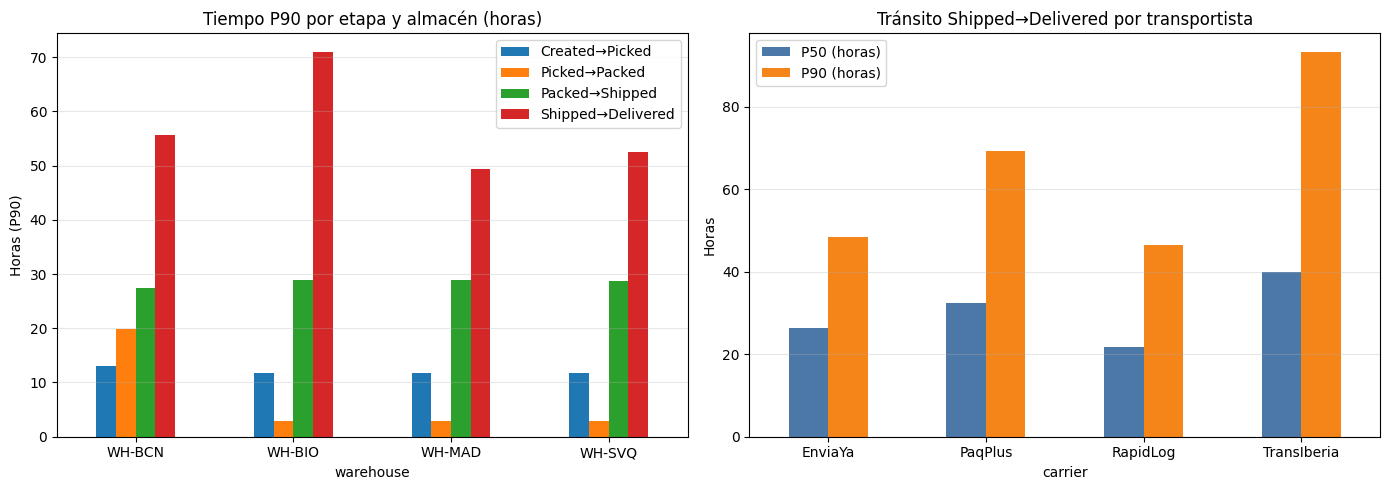

In [2]:
durations = flow.stage_durations(events)
p_wh = flow.percentiles(durations, by=["warehouse"])
p_carrier = flow.percentiles(durations, by=["carrier"])
p_month = flow.percentiles(durations, by=["month"])

display(p_wh)
display(p_carrier)
display(p_month)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
p90_cols = ["created_to_picked_p90", "picked_to_packed_p90", "packed_to_shipped_p90", "shipped_to_delivered_p90"]
labels = ["Created→Picked", "Picked→Packed", "Packed→Shipped", "Shipped→Delivered"]

p_wh_plot = p_wh.set_index("warehouse")[p90_cols]
p_wh_plot.columns = labels
p_wh_plot.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Tiempo P90 por etapa y almacén (horas)")
axes[0].set_ylabel("Horas (P90)")
axes[0].grid(axis="y", alpha=0.3)

p_car_plot = p_carrier.set_index("carrier")[["shipped_to_delivered_p50", "shipped_to_delivered_p90"]]
p_car_plot.columns = ["P50 (horas)", "P90 (horas)"]
p_car_plot.plot(kind="bar", ax=axes[1], rot=0, color=["#4C78A8", "#F58518"])
axes[1].set_title("Tránsito Shipped→Delivered por transportista")
axes[1].set_ylabel("Horas")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES / "flujo_p50_p90_etapas.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. WIP diario y cuello de botella

WIP medio diario: 720.4 | WIP máximo: 1401


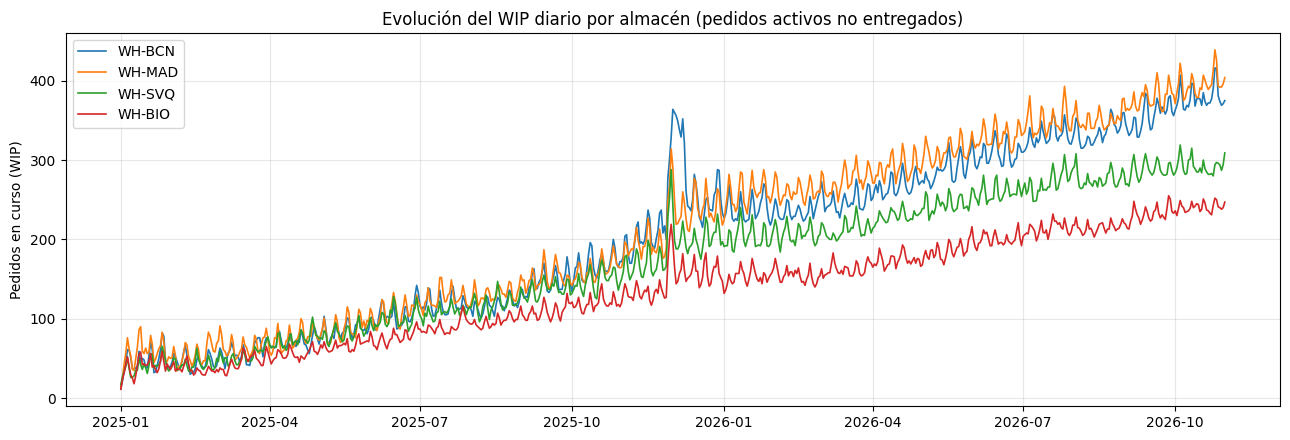

In [3]:
wip = flow.daily_wip(events)
print("WIP medio diario:", round(wip["wip_total"].mean(), 1), "| WIP máximo:", int(wip["wip_total"].max()))

fig, ax = plt.subplots(figsize=(13, 4.5))
for wh in ["WH-BCN", "WH-MAD", "WH-SVQ", "WH-BIO"]:
    if wh in wip.columns:
        ax.plot(wip["date"], wip[wh], label=wh, linewidth=1.2)
ax.set_title("Evolución del WIP diario por almacén (pedidos activos no entregados)")
ax.set_ylabel("Pedidos en curso (WIP)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES / "flujo_wip_diario.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Recomendación operativa: pedidos que requieren intervención hoy

In [4]:
action_orders = flow.orders_needing_action(events, orders, today=pd.Timestamp(DATA_END))
print(f"Total pedidos a intervenir hoy: {len(action_orders)}")
display(action_orders.groupby(["warehouse", "current_stage", "risk_level"]).size().unstack(fill_value=0))
display(action_orders.head(15))

Total pedidos a intervenir hoy: 8


,risk_level,Riesgo alto,Vencido
warehouse,current_stage,,
WH-BCN,shipped,1,1
WH-BIO,shipped,1,1
WH-MAD,shipped,1,2
WH-SVQ,shipped,0,1


,order_id,channel,warehouse,carrier,current_stage,created_ts,promised_ts,hours_to_promise,risk_level,recommended_action
0,NR0077969,app,WH-BCN,TransIberia,shipped,2026-10-26 19:35:40,2026-10-29 19:35:40,-52.4,Vencido,Escalar incidencia con transportista TransIber...
1,NR0078103,web,WH-MAD,TransIberia,shipped,2026-10-27 20:40:19,2026-10-30 20:40:19,-27.3,Vencido,Escalar incidencia con transportista TransIber...
2,NR0078122,web,WH-BIO,PaqPlus,shipped,2026-10-27 21:50:38,2026-10-30 21:50:38,-26.2,Vencido,Escalar incidencia con transportista PaqPlus y...
3,NR0078185,app,WH-MAD,TransIberia,shipped,2026-10-28 17:10:51,2026-10-31 17:10:51,-6.8,Vencido,Escalar incidencia con transportista TransIber...
4,NR0078218,app,WH-SVQ,TransIberia,shipped,2026-10-28 21:24:27,2026-10-31 21:24:27,-2.6,Vencido,Escalar incidencia con transportista TransIber...
5,NR0078254,app,WH-BIO,TransIberia,shipped,2026-10-29 10:46:01,2026-11-01 10:46:01,10.8,Riesgo alto,Escalar incidencia con transportista TransIber...
6,NR0078284,web,WH-BCN,EnviaYa,shipped,2026-10-29 16:22:12,2026-11-01 16:22:12,16.4,Riesgo alto,Escalar incidencia con transportista EnviaYa y...
7,NR0078296,app,WH-MAD,PaqPlus,shipped,2026-10-29 17:52:20,2026-11-01 17:52:20,17.9,Riesgo alto,Escalar incidencia con transportista PaqPlus y...
